# Supplementary Figure S9i. Overlap of neuronal-*cis*-glial-*trans* events with cell-proportion QTL

Fraction of candidate neuronal-*cis* / glial-*trans* colocalization events (CoS) whose colocalized variant set contains at least one variant (exact chr:pos:ref:alt match) from a cell-proportion-QTL credible set (CS50; 3,860 unique variants). Full dataset (top): CoS among the 4,023 *cis*-*trans* loci with a DeJager *cis*-Exc or *cis*-Inh signal and a glial (Mic, Ast, Oli, OPC) *trans*-eGene or *trans*-eProgram signal (1,694 CoS; 3 overlap), per *cis*-neuron x glial pair. Subsamples (bottom): *cis*-Exc rows only, glial *trans*-eGene (only *trans*-eGene was mapped in the subsample runs; 1/449, 0/492, 0/515 CoS overlap for 100K/200K/300K). These sets are not restricted to disjoint cell-type configurations, and a CoS can count in several pairs. `res$overall` gives the overall fractions. Descriptive; no statistical test.

Input: `data/Figure_S9i_propQTL_overlap.rds`

In [1]:
library(ggplot2)
library(scales)
library(patchwork)
res <- readRDS("data/Figure_S9i_propQTL_overlap.rds")
res$overall
res$pairs

dataset,trans_definition,total_CoS,overlap_CoS,overlap_fraction
<chr>,<chr>,<int>,<int>,<dbl>
Full,trans-eGene or trans-eProgram,1694,3,0.001770956
100K,trans-eGene,449,1,0.002227171
200K,trans-eGene,492,0,0.000000000
300K,trans-eGene,515,0,0.000000000


panel,row_id,cis_ct,trans_ct,total_CoS,overlap_CoS,overlap_fraction
<chr>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>
Full dataset,Exc,Exc,Mic,605,2,0.003305785
Full dataset,Exc,Exc,Ast,726,3,0.004132231
Full dataset,Exc,Exc,Oli,712,3,0.004213483
Full dataset,Exc,Exc,OPC,738,2,0.002710027
Full dataset,Inh,Inh,Mic,413,2,0.004842615
Full dataset,Inh,Inh,Ast,480,2,0.004166667
Full dataset,Inh,Inh,Oli,440,2,0.004545455
Full dataset,Inh,Inh,OPC,477,1,0.002096436
Excitatory-neuron subsamples,100K,Exc,Mic,62,0,0.000000000


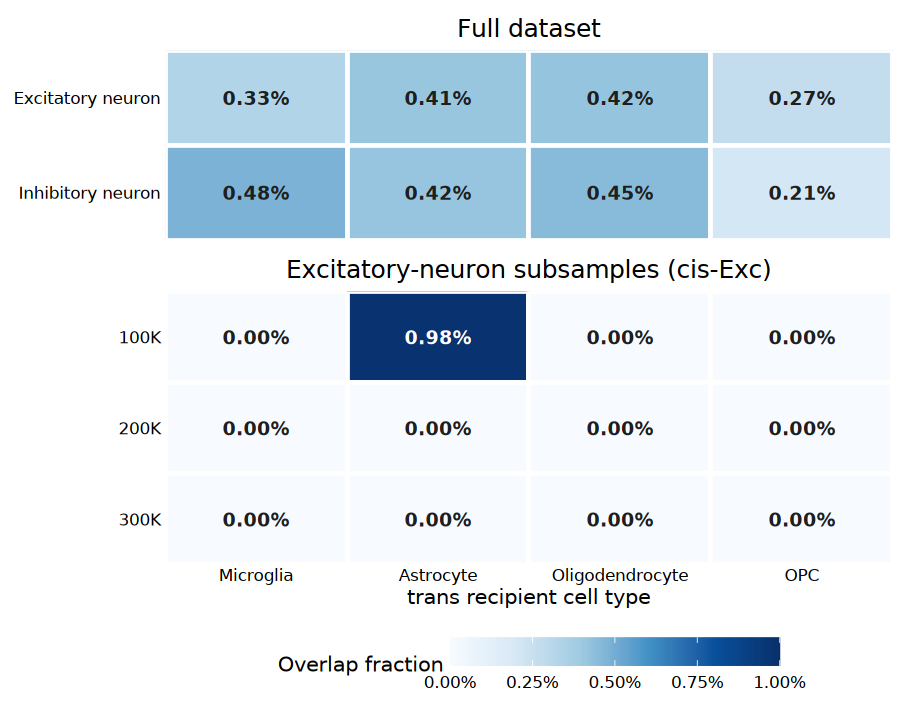

In [2]:
d <- res$pairs
d$trans_ct <- factor(d$trans_ct, levels = c("Mic", "Ast", "Oli", "OPC"),
                     labels = c("Microglia", "Astrocyte", "Oligodendrocyte", "OPC"))
upper <- ceiling(max(d$overlap_fraction) * 1000) / 1000
d$txt <- ifelse(d$overlap_fraction > 0.55 * upper, "white", "grey12")
fill_sc <- scale_fill_gradientn(colours = c("#F7FBFF", "#D7E8F5", "#9ECAE1", "#4292C6", "#08519C", "#08306B"),
                                limits = c(0, upper), labels = label_percent(accuracy = 0.01),
                                name = "Overlap fraction")
heat <- function(x, title, ylev, ylab) {
  x$row_id <- factor(x$row_id, levels = rev(ylev), labels = rev(ylab))
  ggplot(x, aes(x = trans_ct, y = row_id, fill = overlap_fraction)) +
    geom_tile(colour = "white", linewidth = 1) +
    geom_text(aes(label = percent(overlap_fraction, accuracy = 0.01), colour = txt),
              size = 4, fontface = "bold") +
    fill_sc + scale_colour_identity() +
    scale_x_discrete(expand = c(0, 0)) + scale_y_discrete(expand = c(0, 0)) +
    labs(x = NULL, y = NULL, title = title) +
    theme_classic(base_size = 12) +
    theme(axis.line = element_blank(), axis.ticks = element_blank(),
          plot.title = element_text(hjust = 0.5))
}
p_full <- heat(d[d$panel == "Full dataset", ], "Full dataset",
               c("Exc", "Inh"), c("Excitatory neuron", "Inhibitory neuron")) +
  theme(axis.text.x = element_blank())
p_sub <- heat(d[d$panel != "Full dataset", ], "Excitatory-neuron subsamples (cis-Exc)",
              c("100K", "200K", "300K"), c("100K", "200K", "300K")) +
  labs(x = "trans recipient cell type")

options(repr.plot.width = 7.6, repr.plot.height = 6)
p_full / p_sub + plot_layout(heights = c(0.9, 1.3), guides = "collect") &
  theme(legend.position = "bottom", legend.key.width = grid::unit(1.4, "cm"))